In [ ]:
#pip install -q python-dotenv numpy pandas scikit-learn transformers datasets torch huggingface_hub --upgrade

In [1]:
import os
import random
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from pathlib import Path

from huggingface_hub import PyTorchModelHubMixin
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from transformers import DataCollatorWithPadding
from sklearn.model_selection import GroupShuffleSplit
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

load_dotenv()
HF_READ_TOKEN = os.getenv("HF_READ_TOKEN")
HF_WRITE_TOKEN = os.getenv("HF_WRITE_TOKEN")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


In [2]:
# Encoder model
MODEL_NAME = "answerdotai/ModernBERT-base"

# Model params
MAX_LENGTH = 6000
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
EPOCHS = 10
LR = 1e-4
HEAD_HIDDEN = 384
DROPOUT_P = 0.2
WARMUP_RATIO = 0.06

EARLY_STOPPING_PATIENCE = 2
MIN_DELTA = 0.001

# headers: id,assignment_context,previous_conversation,user_query,assistant_response, irrelevancy,solution_proximality
TRAIN_VAL_DIR = "../lab_exercise_dataset_turnwise_openai"
TEST_DIR = "../golden_dataset_turnwise_openai"
EXTRA_POSITIVES_PATH = "solution_proximality_fresh_positives_50.csv"
VAL_SIZE = 0.2
LABEL_COL = "solution_proximality"  # 1 = direct solution, 0 = general guidance

OUTPUT_DIR = "../solution_proximality_modernbert"
BEST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "best.pt")
LAST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "last.pt")
os.makedirs(OUTPUT_DIR, exist_ok=True)

HISTORY_PATH = os.path.join(OUTPUT_DIR, "training_history.csv")
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

HF_REPO_ID = os.getenv("HF_SOLUTION_PROXIMALITY_REPO_ID")
if not HF_READ_TOKEN or not HF_WRITE_TOKEN or not HF_REPO_ID:
    raise ValueError("Set HF_READ_TOKEN, HF_WRITE_TOKEN, and HF_SOLUTION_PROXIMALITY_REPO_ID in your environment before training.")

In [3]:
from pathlib import Path
import pandas as pd

files = sorted(Path(TRAIN_VAL_DIR).glob("*.csv"))

df = pd.read_csv(files[0])

print(files[0].name)
print(
    df.tail(4)[
        ["solution_proximality", "user_query", "assistant_response"]
    ]
)

bacse102_0_1_knapsack_using_dynamic_programming_scored.csv
   solution_proximality                                         user_query  \
40                   no                                    in snippet code   
41                   no      // TODO: Output the result basic snippet code   
42                   no     // TODO: Handle invalid input cases codesippet   
43                   no  // TODO: Handle invalid input cases give the b...   

                                   assistant_response  
40  ```java\n// Basic structure for filling the DP...  
41  ```java\n// Basic structure for outputting the...  
42  The AI Mentor is designed to help you learn an...  
43  ```java\n// Basic structure for input validati...  


In [4]:
from pathlib import Path
import pandas as pd

def load_folder(path):
    files = sorted(Path(path).glob("*.csv"))
    if not files:
        raise ValueError(f"No CSV files found in {path}")

    frames = []
    for file in files:
        df = pd.read_csv(file)
        df["is_synthetic"] = False
        df["source_file"] = file.name

        if "previous_conversation" in df.columns:
            df["previous_conversation"] = df["previous_conversation"].fillna("")

        frames.append(df)

    return pd.concat(frames, ignore_index=True)
    


train_val_df = load_folder(TRAIN_VAL_DIR)
test_df = load_folder(TEST_DIR)
print("Total rows:", len(train_val_df))
print("Synthetic rows:", train_val_df["is_synthetic"].sum())
print("Real rows:", (~train_val_df["is_synthetic"]).sum())

print("\nSynthetic label distribution:")
print(
    train_val_df.loc[
        train_val_df["is_synthetic"],
        LABEL_COL
    ].value_counts()
)

# train_df.head()

Total rows: 2616
Synthetic rows: 0
Real rows: 2616

Synthetic label distribution:
Series([], Name: count, dtype: int64)


In [5]:
from IPython.display import display

positive_examples = train_val_df.loc[
    train_val_df[LABEL_COL]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .fillna(False)
].copy().reset_index(drop=True)

positive_examples["review_index"] = positive_examples.index
positive_examples["response_preview"] = (
    positive_examples["assistant_response"]
    .fillna("")
    .str.slice(0, 180)
)

print(f"Original positive examples: {len(positive_examples)}")

display(positive_examples[
    [
        c for c in [
            "review_index", "source_file", "id",
            "assignment_id", "user_query", "response_preview",
        ]
        if c in positive_examples.columns
    ]
])


def show_positive(index, show_trace=False):
    row = positive_examples.iloc[index]

    print(f"Example {index + 1}/{len(positive_examples)}")
    print(f"Source: {row.get('source_file', '')} | ID: {row['id']}")

    fields = [
        ("ASSIGNMENT", "assignment_context"),
        ("PRECEDING CONVERSATION", "previous_conversation"),
        ("CURRENT USER QUERY", "user_query"),
        ("CURRENT ASSISTANT RESPONSE", "assistant_response"),
    ]

    if show_trace:
        fields.append(("GRANITE REASONING", f"{LABEL_COL}_trace"))

    for heading, column in fields:
        value = row.get(column, "")
        print(f"\n{heading}:\n{'' if pd.isna(value) else value}")


for index in range(len(positive_examples)):
    print("\n" + "=" * 80)
    show_positive(index)

Original positive examples: 245


,review_index,source_file,id,assignment_id,user_query,response_preview
0,0,bacse102_abstract_concept_scored.csv,1_turn_001,bacse102_abstract_concept,import java.util.Scanner;\n\nabstract class Em...,Let's walk through your code carefully to unde...
1,1,bacse102_climbing_stairs_count_ways_using_dyna...,0_turn_002,bacse102_climbing_stairs_count_ways_using_dyna...,static int countWays(int n) {\n // TODO...,You're still not using the `memo` HashMap corr...
2,2,bacse102_climbing_stairs_count_ways_using_dyna...,0_turn_003,bacse102_climbing_stairs_count_ways_using_dyna...,static int countWays(int n) {\n // TODO...,"You're making progress, but there are still so..."
3,3,bacse102_climbing_stairs_count_ways_using_dyna...,0_turn_007,bacse102_climbing_stairs_count_ways_using_dyna...,static int countWays(int n) {\n // TODO...,Perfect! Now your `countWays` method looks cor...
4,4,bacse102_climbing_stairs_count_ways_using_dyna...,0_turn_009,bacse102_climbing_stairs_count_ways_using_dyna...,import java.util.HashMap;\nimport java.util.Sc...,I notice there's a syntax issue in your curren...
...,...,...,...,...,...,...
240,240,bacse102_week8_ips_2_p02_2_scored.csv,5_turn_001,bacse102_week8_ips_2_p02_2,check,Let me walk through your code step by step to ...
241,241,bacse102_week8_ips_2_p02_2_scored.csv,5_turn_002,bacse102_week8_ips_2_p02_2,what is wrong with a and b,Looking at your comparator more carefully:\n\n...
242,242,bacse102_week8_ips_2_p02_2_scored.csv,6_turn_001,bacse102_week8_ips_2_p02_2,Main.java:27: error: incompatible types: Objec...,Hello! I see you're working on a Java program ...
243,243,bacse102_week8_ips_2_p02_2_scored.csv,6_turn_004,bacse102_week8_ips_2_p02_2,i declatred,"I see you mentioned you declared something, bu..."



Example 1/245
Source: bacse102_abstract_concept_scored.csv | ID: 1_turn_001

ASSIGNMENT:
Assignment Title: Abstract concept

Assignment Question:
A company wants to calculate the final salary of its employees based on their basic salary and bonus.
Design a Java program using an abstract class Employee. The abstract class should contain the employee's name, basic salary, bonus, and final salary. It should also contain an abstract method calculateSalary() to calculate the final salary and a concrete method displayDetails() to display the employee information.
Create a class Developer that extends the Employee class and implements the calculateSalary() method.
The final salary of the developer is calculated as:
Final Salary = Basic Salary + Bonus
The program should read the employee name, basic salary, and bonus as input and display the employee details and final salary.
Input Format
The input consists of three lines:
Employee Name
Basic Salary
Bonus
- Employee Name is a string.
- Basic 

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)

train_idx, val_idx = next(
    splitter.split(
        train_val_df,
        groups=train_val_df["assignment_id"]
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)
extra_train_df = pd.read_csv(EXTRA_POSITIVES_PATH)

NEGATIVE_CAP = 1250

labels = train_df[LABEL_COL].astype("string").str.strip().str.lower()
positives = train_df.loc[labels.eq("yes").fillna(False)].copy()
negatives = train_df.loc[labels.eq("no").fillna(False)].copy()
excluded = len(train_df) - len(positives) - len(negatives)

if positives.empty or negatives.empty:
    raise ValueError("Training data must contain both yes and no labels.")

print("Original counts:", {"yes": len(positives), "no": len(negatives)})
print("Excluded missing/invalid labels:", excluded)

# Undersample negatives.
negatives = negatives.sample(
    n=min(NEGATIVE_CAP, len(negatives)),
    random_state=SEED,
)

# Keep every positive, then sample additional copies.
extra_count = 150
extra_positives = positives.sample(
    n=extra_count,
    replace=True,
    random_state=SEED,
)

train_df = (
    pd.concat(
        [positives, negatives, extra_train_df, extra_positives],
        ignore_index=True,
    )
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
train_df[LABEL_COL] = (
    train_df[LABEL_COL].astype("string").str.strip().str.lower()
)

print("Original positive rows retained:", len(positives))
print("Additional positive copies:", extra_count)
print("Final counts:\n", train_df[LABEL_COL].value_counts())

"""assert train_assignments.isdisjoint(val_assignments)

print("Train:", train_df.shape, "| assignments:", len(train_assignments))
print("Val:", val_df.shape, "| assignments:", len(val_assignments))
print("Test:", test_df.shape, "| assignments:", len(test_assignments))"""

Original counts: {'yes': 181, 'no': 2038}
Excluded missing/invalid labels: 0
Original positive rows retained: 181
Additional positive copies: 150
Final counts:
 solution_proximality
no     1250
yes     381
Name: count, dtype: int64[pyarrow]


'assert train_assignments.isdisjoint(val_assignments)\n\nprint("Train:", train_df.shape, "| assignments:", len(train_assignments))\nprint("Val:", val_df.shape, "| assignments:", len(val_assignments))\nprint("Test:", test_df.shape, "| assignments:", len(test_assignments))'

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_READ_TOKEN)

def check_lengths(df):
    lengths = []

    for _, row in df.iterrows():
        text = (
            f"[ASSIGNMENT]\n{str(row['assignment_context']).strip()}\n\n"
            f"[PREVIOUS CONVERSATION]\n{str(row['previous_conversation']).strip()}\n\n"
            f"[CURRENT USER QUERY]\n{str(row['user_query']).strip()}\n\n"
            f"[CURRENT ASSISTANT RESPONSE]\n{str(row['assistant_response']).strip()}"
        )

        lengths.append(len(tokenizer(text, add_special_tokens=True)["input_ids"]))

    lengths = np.array(lengths)

    print("Median:", np.median(lengths))
    print("95th percentile:", np.percentile(lengths, 95))
    print("Maximum:", lengths.max())
    print("Over 4096:", np.sum(lengths > MAX_LENGTH), "/", len(lengths))



check_lengths(train_df)
check_lengths(val_df)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (9447 > 8192). Running this sequence through the model will result in indexing errors


Median: 961.0
95th percentile: 4235.0
Maximum: 10972
Over 4096: 31 / 1631
Median: 752.0
95th percentile: 1979.7999999999995
Maximum: 5189
Over 4096: 0 / 397


In [8]:
print("\nTrain labels:")
print(train_df[LABEL_COL].value_counts())

print("\nValidation labels:")
print(val_df[LABEL_COL].value_counts())


Train labels:
solution_proximality
no     1250
yes     381
Name: count, dtype: int64[pyarrow]

Validation labels:
solution_proximality
no     333
yes     64
Name: count, dtype: int64


In [9]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)


class ProximalityDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=MAX_LENGTH):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        assignment = str(row["assignment_context"]).strip()
        previous = str(row["previous_conversation"]).strip()
        query = str(row["user_query"]).strip()
        response = str(row["assistant_response"]).strip()

        text = (
            f"[ASSIGNMENT]\n{assignment}\n\n"
            f"[PREVIOUS CONVERSATION]\n{previous}\n\n"
            f"[CURRENT USER QUERY]\n{query}\n\n"
            f"[CURRENT ASSISTANT RESPONSE]\n{response}"
        )

        enc = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
        )

        item = {
            "input_ids": enc["input_ids"],
            "attention_mask": enc["attention_mask"],
            "label": 1 if str(row[LABEL_COL]).strip().lower() == "yes" else 0,
        }

        return item


train_ds = ProximalityDataset(train_df, tokenizer)
val_ds = ProximalityDataset(val_df, tokenizer)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

In [10]:
class ProximalityClassifier(nn.Module, PyTorchModelHubMixin):
    def __init__(self, model_name=MODEL_NAME, 
                 hidden_size=768,  # 1024 for ModernBERT-large
                 head_hidden=HEAD_HIDDEN,
                 dropout_p=DROPOUT_P, 
                 num_labels=2):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, token=HF_READ_TOKEN)
        self.head = nn.Sequential(
            nn.Linear(hidden_size, head_hidden),
            nn.GELU(),
            nn.Dropout(dropout_p),
            nn.Linear(head_hidden, num_labels),
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0, :]   # [CLS] pooling
        logits = self.head(cls_repr)
        return logits

model = ProximalityClassifier().to(DEVICE)
for p in model.encoder.parameters():
    p.requires_grad_(False)
    p.grad = None
print(model)

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ProximalityClassifier(
  (encoder): ModernBertModel(
    (embeddings): ModernBertEmbeddings(
      (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
      (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): ModernBertEncoderLayer(
        (attn_norm): Identity()
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
          (Wo): Linear(in_features=768, out_features=768, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=768, out_features=2304, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=1152, out_features=768, bias=False)
        )
      )
      (1-21): 21 x ModernBertEncoderLa

In [11]:
label_counts = train_df[LABEL_COL].str.lower().value_counts()
print("Label counts (train):\n", label_counts)

n_total = label_counts.sum()
n_classes = 2

counts_by_id = {
    0: label_counts.get("no", 0),   # general guidance
    1: label_counts.get("yes", 0),  # direct answer
}

class_weights = torch.tensor(
    [n_total / (n_classes * max(counts_by_id[c], 1)) for c in range(n_classes)],
    dtype=torch.float,
).to(DEVICE)
print("Class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights, reduction="none")

Label counts (train):
 solution_proximality
no     1250
yes     381
Name: count, dtype: int64[pyarrow]
Class weights: tensor([0.6524, 2.1404], device='cuda:0')


In [12]:
# Training Hyperparams
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps_per_epoch = (len(train_loader) + GRAD_ACCUM_STEPS - 1) // GRAD_ACCUM_STEPS
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)


def run_epoch(loader, train_mode=True):
    model.train() if train_mode else model.eval()
    model.encoder.eval()

    total_loss = 0.0
    total_tokens = 0
    all_preds, all_labels, all_probs = [], [], []

    context = torch.enable_grad() if train_mode else torch.no_grad()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    if train_mode:
        optimizer.zero_grad()

    with context:
        progress = tqdm(
            loader,
            desc="Training" if train_mode else "Validation",
            leave=False
        )

        for batch_idx, batch in enumerate(progress):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            total_tokens += int(attention_mask.sum().item())

            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels).mean()

            if train_mode:
                scaled_loss = loss / GRAD_ACCUM_STEPS
                scaled_loss.backward()

                should_step = (
                    (batch_idx + 1) % GRAD_ACCUM_STEPS == 0
                    or (batch_idx + 1) == len(loader)
                )

                if should_step:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad()

            total_loss += loss.item() * input_ids.size(0)

            probs = torch.softmax(logits, dim=-1)[:, 1]
            preds = torch.argmax(logits, dim=-1)

            all_probs.extend(probs.detach().cpu().tolist())
            all_preds.extend(preds.detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())

            progress.set_postfix(loss=f"{loss.item():.4f}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    avg_loss = total_loss / len(loader.dataset)

    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )

    pos_precision, pos_recall, pos_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="binary", zero_division=0
    )

    accuracy = accuracy_score(all_labels, all_preds)
    balanced_accuracy = balanced_accuracy_score(all_labels, all_preds)

    roc_auc = (
        roc_auc_score(all_labels, all_probs)
        if len(set(all_labels)) == 2 else float("nan")
    )

    pr_auc = (
        average_precision_score(all_labels, all_probs)
        if len(set(all_labels)) == 2 else float("nan")
    )

    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_preds,
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if fp + tn else float("nan")

    stats = {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,

        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,

        "positive_precision": pos_precision,
        "positive_recall": pos_recall,
        "positive_f1": pos_f1,

        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "fpr": fpr,

        "predicted_positives": int(sum(all_preds)),

        "seconds": elapsed,
        "samples_per_second": len(loader.dataset) / elapsed,
        "tokens_per_second": total_tokens / elapsed,

        "peak_allocated_vram_gib": (
            torch.cuda.max_memory_allocated() / 1024**3
            if DEVICE.type == "cuda" else float("nan")
        ),

        "peak_reserved_vram_gib": (
            torch.cuda.max_memory_reserved() / 1024**3
            if DEVICE.type == "cuda" else float("nan")
        ),
    }

    return avg_loss, all_preds, all_labels, all_probs, stats


# Training Loop
best_val_pr_auc = -1.0
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")

    train_loss, train_preds, train_labels, train_probs, train_stats = run_epoch(
        train_loader,
        train_mode=True
    )

    val_loss, val_preds, val_labels, val_probs, val_stats = run_epoch(
        val_loader,
        train_mode=False
    )

    print(
        f"predicted positives: "
        f"train={train_stats['predicted_positives']}/{len(train_preds)} | "
        f"val={val_stats['predicted_positives']}/{len(val_preds)}"
    )

    print(
        f"train_loss={train_loss:.4f} "
        f"train_f1={train_stats['macro_f1']:.4f} "
        f"train_pr_auc={train_stats['pr_auc']:.4f} | "
        f"val_loss={val_loss:.4f} "
        f"val_f1={val_stats['macro_f1']:.4f} "
        f"val_pr_auc={val_stats['pr_auc']:.4f} "
        f"val_roc_auc={val_stats['roc_auc']:.4f} | "
        f"VRAM={train_stats['peak_allocated_vram_gib']:.2f} GiB "
        f"time={train_stats['seconds']:.1f}s",
        flush=True
    )

    history.append({
        "epoch": epoch,

        "train_loss": train_loss,
        "val_loss": val_loss,

        "train_macro_f1": train_stats["macro_f1"],
        "val_macro_f1": val_stats["macro_f1"],

        "train_positive_precision": train_stats["positive_precision"],
        "train_positive_recall": train_stats["positive_recall"],
        "train_positive_f1": train_stats["positive_f1"],

        "val_positive_precision": val_stats["positive_precision"],
        "val_positive_recall": val_stats["positive_recall"],
        "val_positive_f1": val_stats["positive_f1"],

        "train_pr_auc": train_stats["pr_auc"],
        "val_pr_auc": val_stats["pr_auc"],

        "train_roc_auc": train_stats["roc_auc"],
        "val_roc_auc": val_stats["roc_auc"],

        "train_fpr": train_stats["fpr"],
        "val_fpr": val_stats["fpr"],

        "train_predicted_positives": train_stats["predicted_positives"],
        "val_predicted_positives": val_stats["predicted_positives"],

        "train_seconds": train_stats["seconds"],
        "val_seconds": val_stats["seconds"],

        "train_samples_per_second": train_stats["samples_per_second"],
        "train_tokens_per_second": train_stats["tokens_per_second"],

        "train_peak_allocated_vram_gib": train_stats["peak_allocated_vram_gib"],
        "train_peak_reserved_vram_gib": train_stats["peak_reserved_vram_gib"],

        "learning_rate": optimizer.param_groups[0]["lr"],
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    torch.save(model.state_dict(), LAST_CHECKPOINT_PATH)

    if val_stats["pr_auc"] > best_val_pr_auc + MIN_DELTA:
        best_val_pr_auc = val_stats["pr_auc"]
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)

        print(
            f"  -> new best val_pr_auc={best_val_pr_auc:.4f}, "
            f"saved to {BEST_CHECKPOINT_PATH}.",
            flush=True
        )

    else:
        epochs_without_improvement += 1

        print(
            f"  -> no significant improvement "
            f"({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})",
            flush=True
        )

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"Early stopping triggered. "
                f"Best val_pr_auc={best_val_pr_auc:.4f}",
                flush=True
            )
            break


Epoch 1/10


Training:   0%|          | 0/1631 [00:00<?, ?it/s]

Validation:   0%|          | 0/397 [00:00<?, ?it/s]

predicted positives: train=672/1631 | val=155/397
train_loss=0.6616 train_f1=0.5660 train_pr_auc=0.3503 | val_loss=0.5594 val_f1=0.5618 val_pr_auc=0.3579 val_roc_auc=0.7261 | VRAM=1.20 GiB time=124.1s
  -> new best val_pr_auc=0.3579, saved to ../solution_proximality_modernbert/best.pt.

Epoch 2/10


Training:   0%|          | 0/1631 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/397 [00:00<?, ?it/s]

predicted positives: train=495/1631 | val=131/397
train_loss=0.4063 train_f1=0.7784 train_pr_auc=0.7359 | val_loss=0.4734 val_f1=0.6567 val_pr_auc=0.4655 val_roc_auc=0.8022 | VRAM=1.20 GiB time=124.2s
  -> new best val_pr_auc=0.4655, saved to ../solution_proximality_modernbert/best.pt.

Epoch 10/10


Training:   0%|          | 0/1631 [00:00<?, ?it/s]

Validation:   0%|          | 0/397 [00:00<?, ?it/s]

predicted positives: train=479/1631 | val=120/397
train_loss=0.4054 train_f1=0.7900 train_pr_auc=0.7394 | val_loss=0.4672 val_f1=0.6746 val_pr_auc=0.4644 val_roc_auc=0.8025 | VRAM=1.20 GiB time=124.3s
  -> no significant improvement (1/2)


In [13]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
)

model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

val_labels = []
val_probs = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=-1)[:, 1]

        val_probs.extend(probs.cpu().tolist())
        val_labels.extend(labels.cpu().tolist())

print(f"ROC-AUC: {roc_auc_score(val_labels, val_probs):.4f}")
print(f"PR-AUC:  {average_precision_score(val_labels, val_probs):.4f}")

thresholds = sorted(set(val_probs))
rows = []

for threshold in thresholds:
    preds = [int(p >= threshold) for p in val_probs]

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        preds,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "macro_f1": f1_score(
            val_labels,
            preds,
            average="macro",
            zero_division=0
        ),
        "precision": precision_score(
            val_labels,
            preds,
            zero_division=0
        ),
        "recall": recall_score(
            val_labels,
            preds,
            zero_division=0
        ),
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    })

threshold_df = pd.DataFrame(rows)

print("\nBest thresholds by macro-F1:")
print(
    threshold_df
    .sort_values(
        ["macro_f1", "fpr"],
        ascending=[False, True]
    )
    .head(20)
    .to_string(index=False)
)

best_row = (
    threshold_df
    .sort_values(
        ["macro_f1", "fpr"],
        ascending=[False, True]
    )
    .iloc[0]
)

BEST_THRESHOLD = float(best_row["threshold"])

print(f"\nSelected threshold: {BEST_THRESHOLD:.8f}")
print(best_row.to_string())

ROC-AUC: 0.8022
PR-AUC:  0.4655

Best thresholds by macro-F1:
 threshold  macro_f1  precision   recall      fpr  tn  fp  fn  tp
  0.594138  0.689368   0.421053 0.625000 0.165165 278  55  24  40
  0.591879  0.686909   0.416667 0.625000 0.168168 277  56  24  40
  0.591313  0.684466   0.412371 0.625000 0.171171 276  57  24  40
  0.594164  0.683942   0.414894 0.609375 0.165165 278  55  25  39
  0.588859  0.682040   0.408163 0.625000 0.174174 275  58  24  40
  0.545881  0.681550   0.393162 0.718750 0.213213 262  71  18  46
  0.586367  0.679630   0.404040 0.625000 0.177177 274  59  24  40
  0.543634  0.679218   0.389831 0.718750 0.216216 261  72  18  46
  0.548248  0.679039   0.391304 0.703125 0.210210 263  70  19  45
  0.559466  0.678507   0.394495 0.671875 0.198198 267  66  21  43
  0.597246  0.678459   0.408602 0.593750 0.165165 278  55  26  38
  0.605224  0.677760   0.411111 0.578125 0.159159 280  53  27  37
  0.585340  0.677236   0.400000 0.625000 0.180180 273  60  24  40
  0.539587  0.

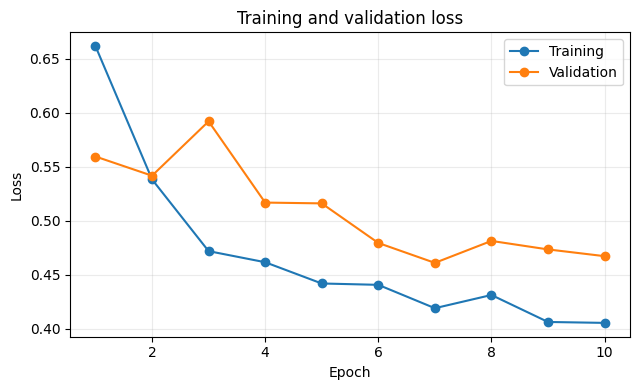

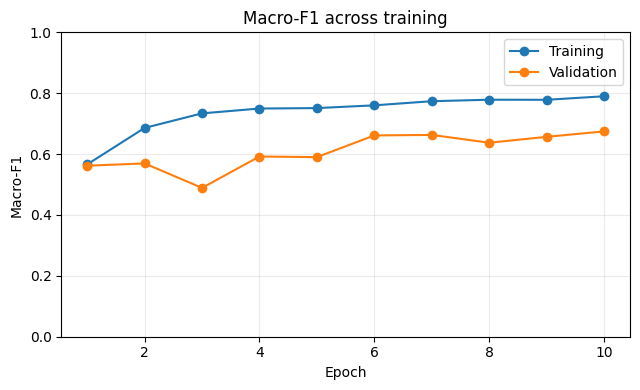

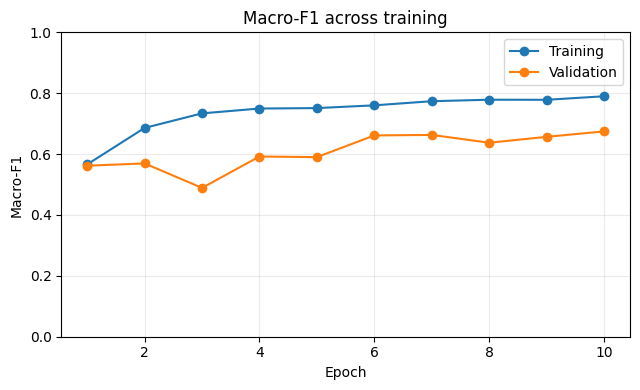

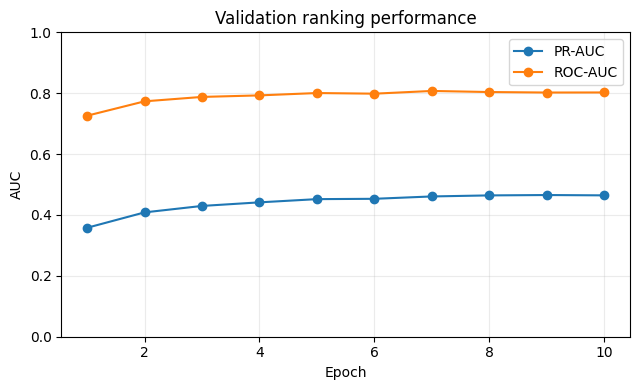

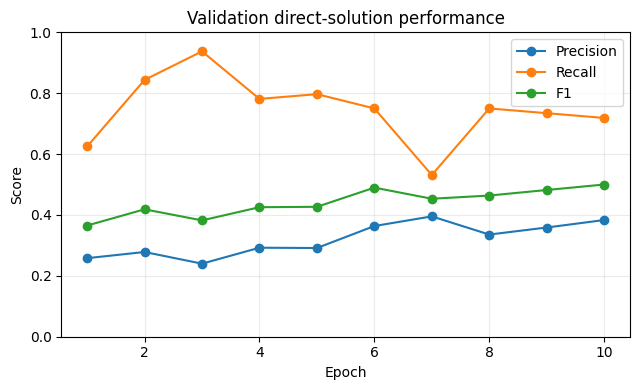

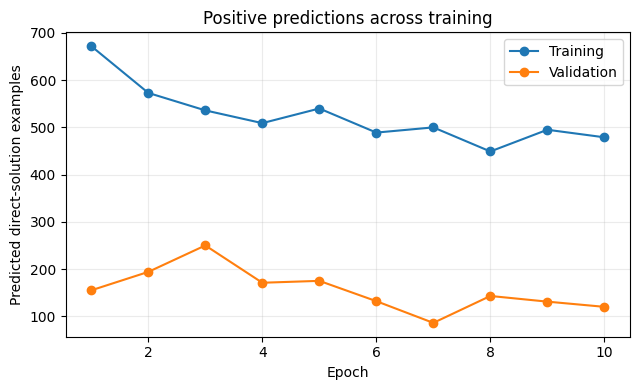

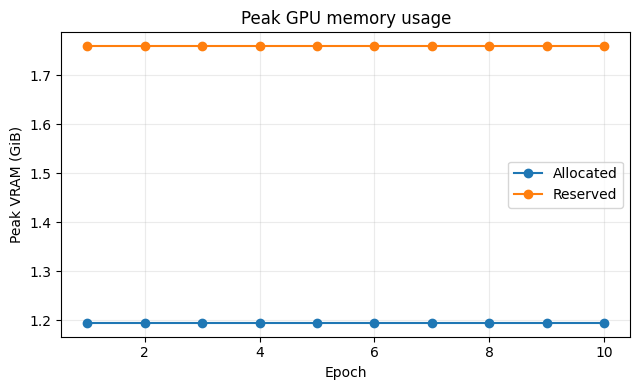

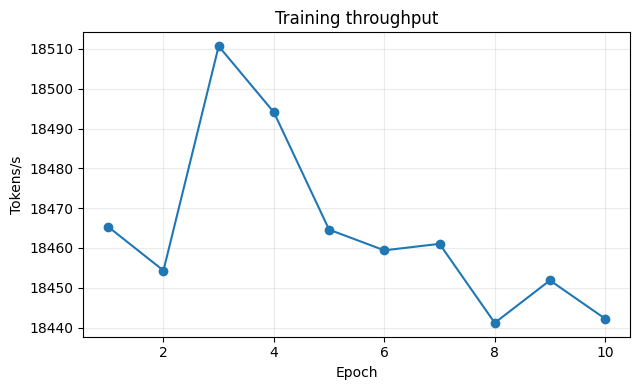

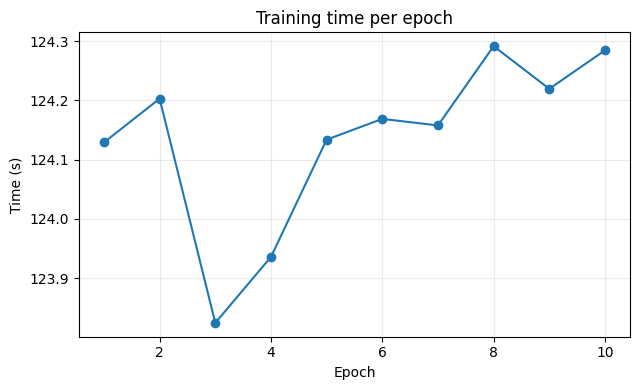

In [14]:
history_df = pd.read_csv(HISTORY_PATH)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(
        os.path.join(FIGURE_DIR, f"{name}.pdf"),
        bbox_inches="tight"
    )
    fig.savefig(
        os.path.join(FIGURE_DIR, f"{name}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and validation loss")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "loss_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Macro-F1 across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "macro_f1_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Macro-F1 across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "macro_f1_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["val_pr_auc"], marker="o", label="PR-AUC")
ax.plot(history_df["epoch"], history_df["val_roc_auc"], marker="o", label="ROC-AUC")

ax.set_xlabel("Epoch")
ax.set_ylabel("AUC")
ax.set_ylim(0, 1)
ax.set_title("Validation ranking performance")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "validation_auc")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["val_positive_precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    history_df["epoch"],
    history_df["val_positive_recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    history_df["epoch"],
    history_df["val_positive_f1"],
    marker="o",
    label="F1"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Validation direct-solution performance")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "validation_positive_metrics")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_predicted_positives"],
    marker="o",
    label="Training"
)

ax.plot(
    history_df["epoch"],
    history_df["val_predicted_positives"],
    marker="o",
    label="Validation"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Predicted direct-solution examples")
ax.set_title("Positive predictions across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "predicted_positives")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_peak_allocated_vram_gib"],
    marker="o",
    label="Allocated"
)

ax.plot(
    history_df["epoch"],
    history_df["train_peak_reserved_vram_gib"],
    marker="o",
    label="Reserved"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Peak VRAM (GiB)")
ax.set_title("Peak GPU memory usage")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "training_vram")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_tokens_per_second"],
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Tokens/s")
ax.set_title("Training throughput")
ax.grid(alpha=0.25)

save_figure(fig, "training_throughput")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_seconds"],
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Time (s)")
ax.set_title("Training time per epoch")
ax.grid(alpha=0.25)

save_figure(fig, "epoch_time")

Validation:   0%|          | 0/397 [00:00<?, ?it/s]

Validation loss: 0.4734
Decision threshold: 0.59413773
PR-AUC:  0.4655
ROC-AUC: 0.8022
                  precision    recall  f1-score   support

general_guidance       0.92      0.83      0.88       333
 direct_solution       0.42      0.62      0.50        64

        accuracy                           0.80       397
       macro avg       0.67      0.73      0.69       397
    weighted avg       0.84      0.80      0.82       397

Confusion matrix (rows=true, cols=pred):
[[278  55]
 [ 24  40]]
False Positive Rate: 0.1652
Macro-F1: 0.6894


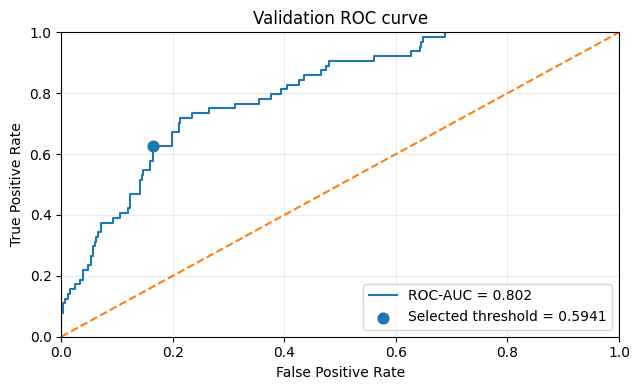

In [15]:
DECISION_THRESHOLD = BEST_THRESHOLD

model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

val_loss, _, val_labels, val_probs, val_stats = run_epoch(
    val_loader,
    train_mode=False
)

# Apply validation-selected threshold instead of argmax / 0.5
val_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in val_probs
]

print(f"Validation loss: {val_loss:.4f}")
print(f"Decision threshold: {DECISION_THRESHOLD:.8f}")
print(f"PR-AUC:  {val_stats['pr_auc']:.4f}")
print(f"ROC-AUC: {val_stats['roc_auc']:.4f}")

print(
    classification_report(
        val_labels,
        val_preds,
        target_names=["general_guidance", "direct_solution"],
        zero_division=0
    )
)

cm = confusion_matrix(val_labels, val_preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows=true, cols=pred):")
print(cm)

print(f"False Positive Rate: {fp / (fp + tn):.4f}")
print(f"Macro-F1: {f1_score(val_labels, val_preds, average='macro'):.4f}")

# ROC curve
fpr_curve, tpr_curve, thresholds_curve = roc_curve(val_labels, val_probs)

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    fpr_curve,
    tpr_curve,
    label=f"ROC-AUC = {val_stats['roc_auc']:.3f}"
)

ax.plot([0, 1], [0, 1], linestyle="--")

# Mark the selected operating point
selected_fpr = fp / (fp + tn)
selected_tpr = tp / (tp + fn)

ax.scatter(
    selected_fpr,
    selected_tpr,
    s=60,
    label=f"Selected threshold = {DECISION_THRESHOLD:.4f}"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Validation ROC curve")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "roc_curve")

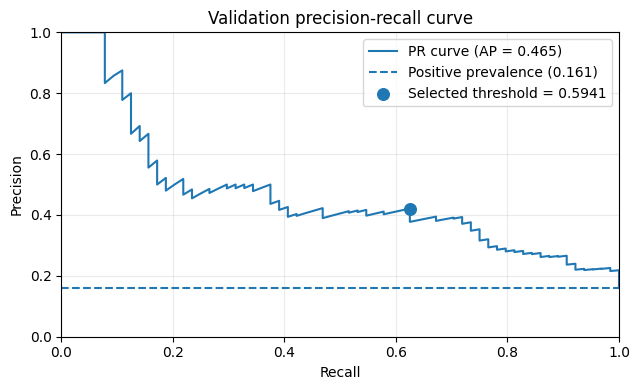

In [16]:
precision_curve, recall_curve, _ = precision_recall_curve(
    val_labels,
    val_probs
)

# Metrics at the selected decision threshold
threshold_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in val_probs
]

selected_precision = precision_score(
    val_labels,
    threshold_preds,
    zero_division=0
)

selected_recall = recall_score(
    val_labels,
    threshold_preds,
    zero_division=0
)

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    recall_curve,
    precision_curve,
    label=f"PR curve (AP = {val_stats['pr_auc']:.3f})"
)

baseline = sum(val_labels) / len(val_labels)

ax.axhline(
    baseline,
    linestyle="--",
    label=f"Positive prevalence ({baseline:.3f})"
)

# Mark selected operating point
ax.scatter(
    selected_recall,
    selected_precision,
    s=70,
    zorder=5,
    label=f"Selected threshold = {DECISION_THRESHOLD:.4f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Validation precision-recall curve")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "precision_recall_curve")

In [17]:
hub_config = {
    "setup_name": "ProximalityModernBERT (2-seg) Linear+GELU+Linear",
    "architectures": ["ProximalityClassifier"],
    "encoder": MODEL_NAME,
    "hidden_size": 768,
    "max_length": MAX_LENGTH,
    "head_hidden": HEAD_HIDDEN,
    "dropout_p": DROPOUT_P,
    "num_labels": 2,
    "label_map": {"0": "general_guidance", "1": "direct_solution"},
}
# This configuration is uploaded with the model in the final notebook cell.

Latency benchmark:   0%|          | 0/397 [00:00<?, ?it/s]

Mean:   36.68 ms
Median: 25.15 ms
P95:    88.51 ms
Max:    418.73 ms


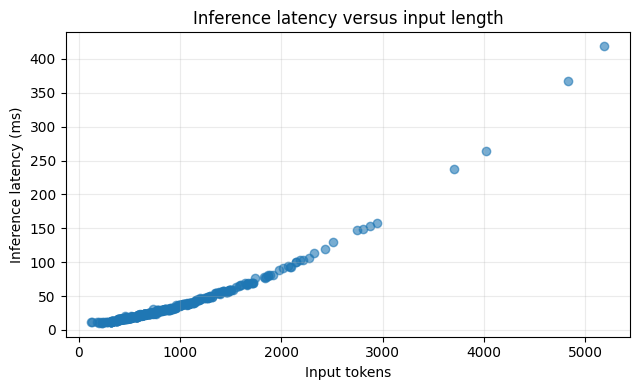

In [18]:
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

latency_rows = []

sample_batch = next(iter(val_loader))

with torch.no_grad():
    input_ids = sample_batch["input_ids"].to(DEVICE)
    attention_mask = sample_batch["attention_mask"].to(DEVICE)

    for _ in range(5):
        _ = model(input_ids, attention_mask)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Latency benchmark"):
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        token_count = int(attention_mask.sum().item())

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        start = time.perf_counter()

        _ = model(input_ids, attention_mask)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        latency_ms = (time.perf_counter() - start) * 1000

        latency_rows.append({
            "tokens": token_count,
            "latency_ms": latency_ms,
            "peak_vram_gib": (
                torch.cuda.max_memory_allocated() / 1024**3
                if DEVICE.type == "cuda" else float("nan")
            )
        })

latency_df = pd.DataFrame(latency_rows)

latency_df.to_csv(
    os.path.join(OUTPUT_DIR, "inference_latency.csv"),
    index=False
)

print(f"Mean:   {latency_df['latency_ms'].mean():.2f} ms")
print(f"Median: {latency_df['latency_ms'].median():.2f} ms")
print(f"P95:    {latency_df['latency_ms'].quantile(0.95):.2f} ms")
print(f"Max:    {latency_df['latency_ms'].max():.2f} ms")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.scatter(
    latency_df["tokens"],
    latency_df["latency_ms"],
    alpha=0.6
)

ax.set_xlabel("Input tokens")
ax.set_ylabel("Inference latency (ms)")
ax.set_title("Inference latency versus input length")
ax.grid(alpha=0.25)

save_figure(fig, "latency_vs_tokens")

In [22]:
synthetic_test_ds = ProximalityDataset(pd.read_csv("solution_proximality_unseen_test_192.csv"), tokenizer)
test_ds = ProximalityDataset(test_df, tokenizer)

test_loader = DataLoader(
    synthetic_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

Validation:   0%|          | 0/192 [00:00<?, ?it/s]

Test loss: 0.9877
Decision threshold: 0.59413773
PR-AUC:  0.6106
ROC-AUC: 0.6143
                  precision    recall  f1-score   support

general_guidance       0.55      0.70      0.61        96
 direct_solution       0.59      0.43      0.49        96

        accuracy                           0.56       192
       macro avg       0.57      0.56      0.55       192
    weighted avg       0.57      0.56      0.55       192

Confusion matrix (rows=true, cols=pred), order=[general_guidance, direct_solution]:
[[67 29]
 [55 41]]
False Positive Rate (general guidance wrongly flagged direct_solution): 0.3021
Macro-F1: 0.5543
Direct-solution precision: 0.5857
Direct-solution recall: 0.4271


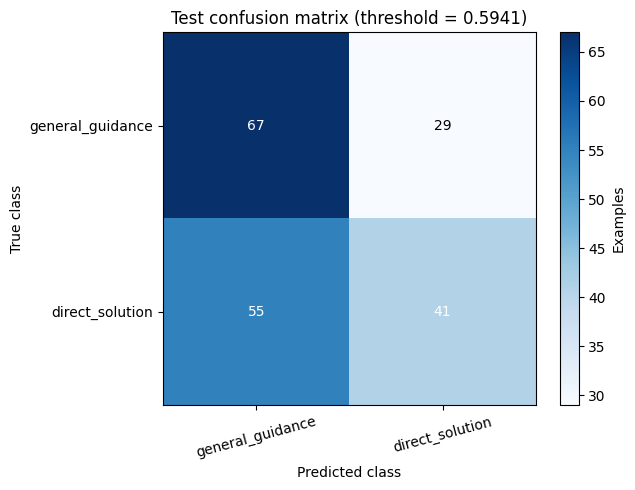

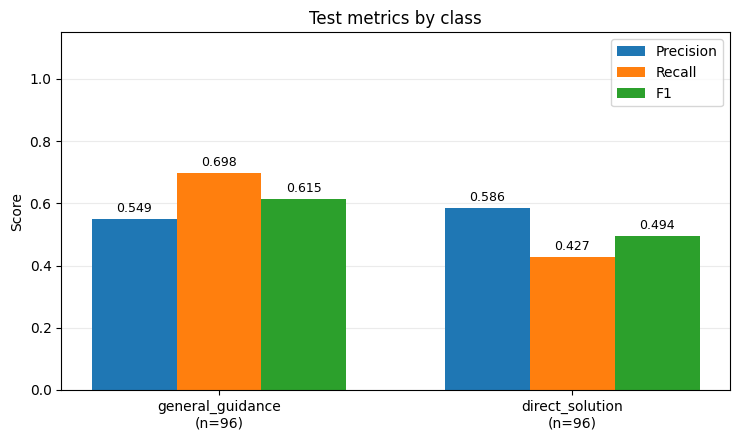

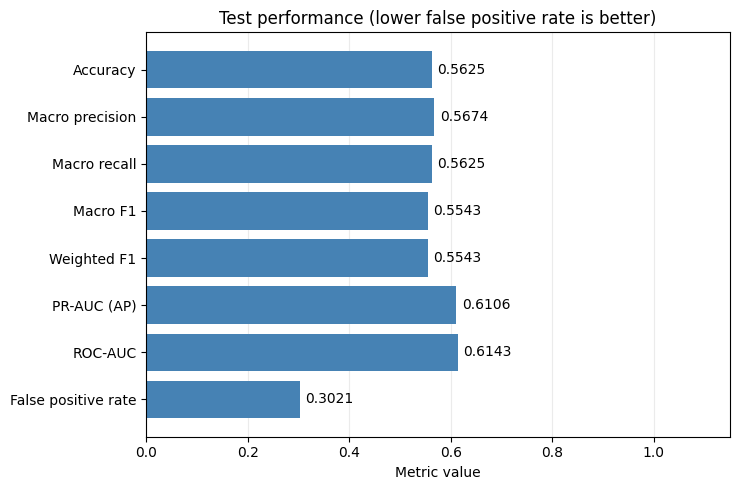

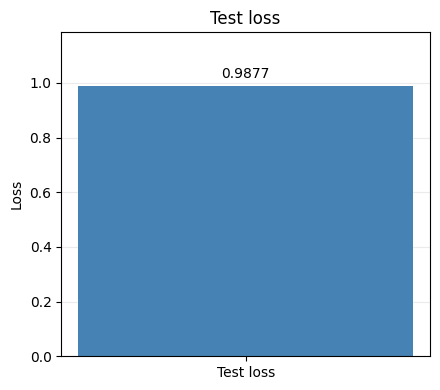

In [23]:
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

test_loss, _, test_labels, test_probs, test_stats = run_epoch(
    test_loader,
    train_mode=False
)

# Apply the frozen validation-selected threshold
test_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in test_probs
]

print(f"Test loss: {test_loss:.4f}")
print(f"Decision threshold: {DECISION_THRESHOLD:.8f}")
print(f"PR-AUC:  {test_stats['pr_auc']:.4f}")
print(f"ROC-AUC: {test_stats['roc_auc']:.4f}")

print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["general_guidance", "direct_solution"],
        zero_division=0
    )
)

cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")

print(
    "Confusion matrix (rows=true, cols=pred), "
    "order=[general_guidance, direct_solution]:"
)
print(cm)

print(
    f"False Positive Rate "
    f"(general guidance wrongly flagged direct_solution): "
    f"{fpr:.4f}"
)

print(
    f"Macro-F1: "
    f"{f1_score(test_labels, test_preds, average='macro', zero_division=0):.4f}"
)

print(
    f"Direct-solution precision: "
    f"{precision_score(test_labels, test_preds, zero_division=0):.4f}"
)

print(
    f"Direct-solution recall: "
    f"{recall_score(test_labels, test_preds, zero_division=0):.4f}"
)

import numpy as np
import matplotlib.pyplot as plt

class_names = ["general_guidance", "direct_solution"]
report = classification_report(
    test_labels,
    test_preds,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

# Confusion matrix
fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Examples")

ax.set_xticks([0, 1], class_names, rotation=15)
ax.set_yticks([0, 1], class_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(
    f"Test confusion matrix (threshold = {DECISION_THRESHOLD:.4f})"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

save_figure(fig, "test_confusion_matrix")

# Per-class precision, recall, F1, and support
fig, ax = plt.subplots(figsize=(7.5, 4.5))
positions = np.arange(2)
width = 0.24

for offset, metric in zip(
    [-1, 0, 1], ["precision", "recall", "f1-score"]
):
    bars = ax.bar(
        positions + offset * width,
        [report[name][metric] for name in class_names],
        width=width,
        label=metric.replace("f1-score", "F1").capitalize(),
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_xticks(
    positions,
    [
        f"{name}\n(n={int(report[name]['support'])})"
        for name in class_names
    ],
)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title("Test metrics by class")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

save_figure(fig, "test_class_metrics")

# Overall metrics
metrics = {
    "Accuracy": float(
        np.mean(np.asarray(test_labels) == np.asarray(test_preds))
    ),
    "Macro precision": report["macro avg"]["precision"],
    "Macro recall": report["macro avg"]["recall"],
    "Macro F1": report["macro avg"]["f1-score"],
    "Weighted F1": report["weighted avg"]["f1-score"],
    "PR-AUC (AP)": test_stats["pr_auc"],
    "ROC-AUC": test_stats["roc_auc"],
    "False positive rate": fpr,
}

fig, ax = plt.subplots(figsize=(7.5, 5))
values = np.asarray(list(metrics.values()), dtype=float)
bars = ax.barh(
    list(metrics),
    np.where(np.isfinite(values), values, 0),
    color="steelblue",
)
ax.bar_label(
    bars,
    labels=[
        f"{value:.4f}" if np.isfinite(value) else "undefined"
        for value in values
    ],
    padding=4,
)

ax.invert_yaxis()
ax.set_xlim(0, 1.15)
ax.set_xlabel("Metric value")
ax.set_title(
    "Test performance (lower false positive rate is better)"
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

save_figure(fig, "test_overall_metrics")

# Loss uses its own scale
fig, ax = plt.subplots(figsize=(4.5, 4))
bars = ax.bar(
    ["Test loss"], [test_loss], color="steelblue", width=0.5
)
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_ylim(0, max(0.1, test_loss * 1.2))
ax.set_ylabel("Loss")
ax.set_title("Test loss")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

save_figure(fig, "test_loss")

In [25]:
import numpy as np
from IPython.display import display

inspection_df = test_ds.df.reset_index(drop=True).copy()
#assert len(inspection_df) == len(test_labels) == len(test_preds)

inspection_df["true_id"] = np.asarray(test_labels, dtype=int)
inspection_df["predicted_id"] = np.asarray(test_preds, dtype=int)

inspection_df["error_type"] = np.select(
    [
        (inspection_df["true_id"] == 0)
        & (inspection_df["predicted_id"] == 1),

        (inspection_df["true_id"] == 1)
        & (inspection_df["predicted_id"] == 0),
    ],
    ["false_positive", "false_negative"],
    default="correct",
)

errors_df = inspection_df.loc[
    inspection_df["error_type"] != "correct"
].copy()

summary_columns = [
    column for column in
    ["source_file", "id", "assignment_id", "error_type", "user_query"]
    if column in errors_df.columns
]

display(errors_df[summary_columns])
print(errors_df["error_type"].value_counts())


def readable(value):
    return "" if pd.isna(value) else str(value)


for error_type in ["false_positive", "false_negative"]:
    subset = errors_df.loc[errors_df["error_type"] == error_type]

    print(f"\n{'=' * 70}")
    print(f"{error_type.upper()}: {len(subset)} examples")

    for index, row in subset.iterrows():
        print(
            f"\n--- Test row {index} | id={row.get('id', index)} "
            f"| source={row.get('source_file', '')} ---"
        )
        class_names = ["general_guidance", "direct_solution"]

        print("True:", class_names[int(row["true_id"])])
        print("Predicted:", class_names[int(row["predicted_id"])])

        print("\nASSIGNMENT:\n" + readable(row["assignment_context"]))
        print(
            "\nPRECEDING CONVERSATION:\n"
            + readable(row.get("previous_conversation", ""))
        )
        print("\nCURRENT USER QUERY:\n" + readable(row["user_query"]))
        print(
            "\nCURRENT ASSISTANT RESPONSE:\n"
            + readable(row["assistant_response"])
        )
        print(
            "\nANNOTATOR EXPLANATION:\n"
            + readable(row.get("solution_proximality_trace", ""))
        )

ValueError: Length of values (192) does not match length of index (330)

In [26]:
import json
import os

EXPORT_DIR = "../solution_proximality_modernbert/hf_export"

model.load_state_dict(
    torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
)
model.eval()

model.save_pretrained(
    EXPORT_DIR,
    config=hub_config
)

tokenizer.save_pretrained(EXPORT_DIR)

inference_config = {
    "decision_threshold": DECISION_THRESHOLD,
    "positive_class_id": 1,
    "positive_label": "direct_solution",
    "negative_label": "general_guidance",
    "score_type": "softmax_probability",
    "checkpoint_selection_metric": "validation_pr_auc",
    "threshold_selection_metric": "validation_macro_f1",
}

with open(
    os.path.join(EXPORT_DIR, "inference_config.json"),
    "w"
) as f:
    json.dump(inference_config, f, indent=2)

print(f"Saved Hugging Face export to {EXPORT_DIR}")

Saved Hugging Face export to ../solution_proximality_modernbert/hf_export


In [ ]:
loaded_tokenizer = AutoTokenizer.from_pretrained(EXPORT_DIR)

loaded_model = ProximalityClassifier.from_pretrained(
    EXPORT_DIR
).to(DEVICE)

loaded_model.eval()

with open(
    os.path.join(EXPORT_DIR, "inference_config.json")
) as f:
    inference_config = json.load(f)

DECISION_THRESHOLD = inference_config["decision_threshold"]

print("Decision threshold:", DECISION_THRESHOLD)

In [ ]:
batch = next(iter(val_loader))

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)

model.eval()
loaded_model.eval()

with torch.no_grad():
    original_logits = model(input_ids, attention_mask)
    loaded_logits = loaded_model(input_ids, attention_mask)

print(
    "Max absolute difference:",
    (original_logits - loaded_logits).abs().max().item()
)

In [ ]:
# Sample Inference Code

import json
import os
import torch
from transformers import AutoTokenizer

EXPORT_DIR = "../solution_proximality_modernbert/hf_export"

# Load tokenizer + model
tokenizer = AutoTokenizer.from_pretrained(EXPORT_DIR)

model = ProximalityClassifier.from_pretrained(
    EXPORT_DIR
).to(DEVICE)

model.eval()

# Load calibrated inference metadata
with open(os.path.join(EXPORT_DIR, "inference_config.json")) as f:
    inference_config = json.load(f)

DECISION_THRESHOLD = inference_config["decision_threshold"]


def predict_solution_proximity(
    assignment_context,
    previous_conversation,
    user_query,
    assistant_response
):
    text = (
        f"[ASSIGNMENT]\n{assignment_context}\n\n"
        f"[PREVIOUS CONVERSATION]\n{previous_conversation}\n\n"
        f"[CURRENT USER QUERY]\n{user_query}\n\n"
        f"[CURRENT ASSISTANT RESPONSE]\n{assistant_response}"
    )

    inputs = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    input_ids = inputs["input_ids"].to(DEVICE)
    attention_mask = inputs["attention_mask"].to(DEVICE)

    with torch.no_grad():
        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        prob_direct_solution = torch.softmax(
            logits,
            dim=-1
        )[0, 1].item()

    predicted_label = (
        "direct_solution"
        if prob_direct_solution >= DECISION_THRESHOLD
        else "general_guidance"
    )

    return {
        "label": predicted_label,
        "prob_direct_solution": prob_direct_solution,
        "threshold": DECISION_THRESHOLD
    }

In [ ]:
# Publish the best checkpoint, custom-head architecture metadata, and tokenizer.
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()
model.push_to_hub(
    HF_REPO_ID,
    token=HF_WRITE_TOKEN,
    config=hub_config,
    commit_message=f"Upload best solution-proximality classifier)",
)
tokenizer.push_to_hub(HF_REPO_ID, token=HF_WRITE_TOKEN, commit_message="Upload tokenizer")
print(f"Uploaded model architecture metadata, backbone and classifier weights, and tokenizer to https://huggingface.co/{HF_REPO_ID}")

In [ ]:
# Run this after the final upload cell (or to use a previously uploaded version).
hub_tokenizer = AutoTokenizer.from_pretrained(HF_REPO_ID, token=HF_READ_TOKEN)
hub_model = ProximalityClassifier.from_pretrained(HF_REPO_ID, token=HF_READ_TOKEN).to(DEVICE)
hub_model.eval()

assignment_context = "Your assignment context here"
previous_conversation = "Previous conversation here"
user_query = "User query here"
assistant_response = "Assistant response here"

text = (
    f"[ASSIGNMENT]\n{assignment_context.strip()}\n\n"
    f"[PREVIOUS CONVERSATION]\n{previous_conversation.strip()}\n\n"
    f"[CURRENT USER QUERY]\n{user_query.strip()}\n\n"
    f"[CURRENT ASSISTANT RESPONSE]\n{assistant_response.strip()}"
)
inputs = hub_tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(DEVICE)
with torch.no_grad():
    predicted_id = hub_model(**inputs).argmax(dim=-1).item()

labels = {0: "general_guidance", 1: "direct_solution"}
print(f"Prediction: {labels[predicted_id]}")